[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/walkerke/geog30323/blob/main/notebooks/assignment-08-geographic-visualization.ipynb)

## Assignment 8: Geographic data visualization and analysis

In this assignment, you'll be making interactive maps of public intoxication violations in Fort Worth, drawn from the same City crime data you worked with in Assignment 6.  You'll explore methods for visualizing large amounts of point data and customize your map's appearance.  You'll then combine the crime data with demographic data from the US Census Bureau to analyze how public intoxication varies across Fort Worth's neighborhoods.

To do this, we'll need a few Python packages that are not pre-installed in Colab.  As we discussed in class, packages can be installed in Colab with `pip`.  Run the cell below to install them; it may take a minute or so to finish.

In [ ]:
!pip install pytidycensus leafmap maplibre mapclassify "ipyvuetify<3"

Let's get started by reading in our data.  In Assignment 6, we requested a table of crime data from the City of Fort Worth's Open Data API.  The City also publishes the same crime data as a geographic layer, in which each record comes with a point location.  I've saved a copy of that layer for 2025 as a GeoJSON file on the course GitHub page.  As you learned in class, GeoPandas can read geographic data directly from a URL with `gp.read_file()`: 

In [2]:
import pandas as pd
import geopandas as gp

crime = gp.read_file("https://raw.githubusercontent.com/walkerke/geog30323/main/data/fort_worth_crime_2025.geojson")

crime.shape

(56936, 5)

Our dataset has 56,936 rows, representing offenses of all types reported to the Fort Worth Police Department in 2025.  Let's take a quick peek at the data: 

In [3]:
crime.head()

,Case_No,Nature_Of_Call,Offense_Desc,BLOCK_ADDRESS,geometry
0,220074885,THEFT,PC 32.55(d)(6) FINANCIAL ABUSE ELDERLY >=$150K,300 W BELKNAP ST,POINT (-97.30272 32.89285)
1,230318026,THEFT,PC 31.03 Theft - Shoplifting,1100 EASTCHASE PKWY,POINT (-97.16744 32.76388)
2,240000329,PENAL CODE,PC 32.21(D) Forgery Financial Instrument,5900 COPPERMILL RD,POINT (-97.30345 32.85107)
3,240001145,THEFT,GC 085-07 Theft under $100- Shoplifting,7900 SOUTH FWY,POINT (-97.32172 32.6346)
4,240099833,SEX REGISTRATION,CCP 62.10(B)(2) FAIL TO COMPLY SEX OFF DUTY TO...,5600 FERNANDER DR.,POINT (-97.40638 32.71519)


As our data come from a geographic layer, GeoPandas has read them in as a GeoDataFrame, with the location of each record stored as a point in the `geometry` column.  The type of offense is found in the `Nature_Of_Call` column, as it was in Assignment 6.  We are interested in public intoxication violations, which we can get with the `.query()` method: 

In [4]:
intox = crime.query('Nature_Of_Call == "PUBLIC INTOXICATION"')

intox.shape

(1064, 5)

This gives us 1,064 rows.  Before we go any further, however, we should make sure we understand what a row in this dataset represents.  Let's take a look at the rows for one case number: 

In [5]:
intox.query('Case_No == "250004693"')

,Case_No,Nature_Of_Call,Offense_Desc,BLOCK_ADDRESS,geometry
3364,250004693,PUBLIC INTOXICATION,LOCAL Local Class C Warrants,2400 W 7TH ST,POINT (-97.3508 32.75111)
3499,250004693,PUBLIC INTOXICATION,GC 080 Public Intoxication,2400 W 7TH ST,POINT (-97.3508 32.75111)


This case shows up twice in our dataset.  Each row represents an _offense_ rather than a call, and a single call can involve more than one offense; in this instance, public intoxication along with a warrant.  If we mapped the data as-is, calls like this one would be counted more than once.  As we are interested in where public intoxication calls take place, we'll keep one row per case with the `.drop_duplicates()` method.  

In [6]:
intox = intox.drop_duplicates(subset = 'Case_No')

intox.shape

(918, 5)

That leaves us with 918 calls.  Some of the calls are missing a location, however.  

In [7]:
null_rows = pd.isnull(intox.geometry)

null_rows.value_counts()

geometry
False    909
True       9
Name: count, dtype: int64

It looks like 9 rows in our dataset are missing location information.  In a regular data analysis workflow, you'd want to do some investigation of these missing values, and ultimately see if there is any systematic bias there.  Another option would be to try to locate as many of these missing values as possible.  As our focus here is learning how to map and analyze geographic data in Python, however, let's forge ahead and drop those rows from our dataset.  

In [8]:
intox = intox.dropna(subset = ['geometry'])

intox.shape

(909, 5)

Our 909 remaining calls are ready to map.  

## Making an interactive map with MapLibre

To make our maps, we'll be using [MapLibre](https://maplibre.org/), an open-source library for interactive web mapping.  MapLibre is written in JavaScript, but we can use it from Python with the __leafmap__ package.  Let's import it and create a map centered on Fort Worth:

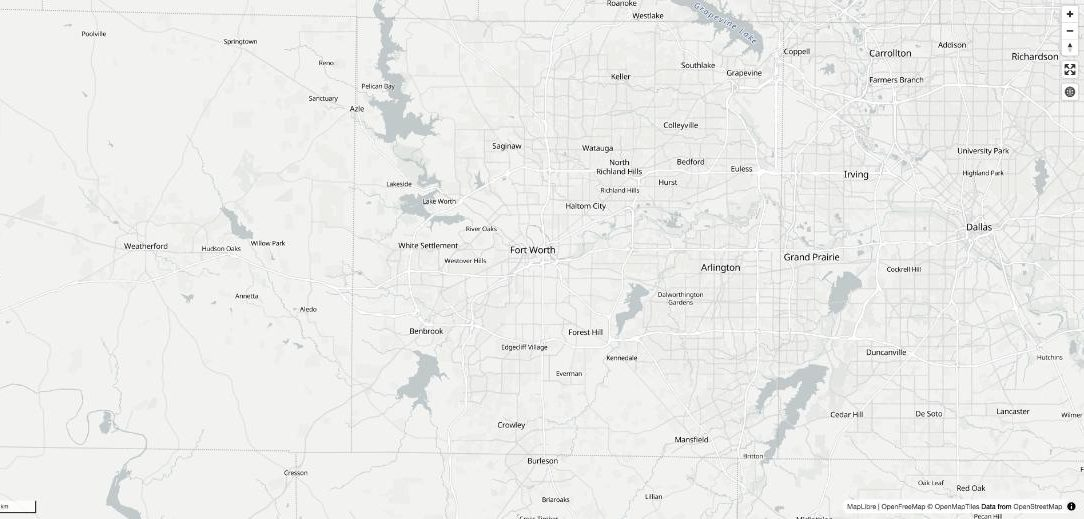

In [9]:
import leafmap.maplibregl as leafmap

# Note that the center is specified as [longitude, latitude]
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m

Pan around the map and zoom in and out.  MapLibre gives you access to _vector tiles_, which are variants of the tiled mapping structure we've discussed in class but which expose the underlying data rather than simply showing images.  This allows for the customization of any component of the map.

The `style` parameter controls the appearance of the basemap.  The style I've used here, `"positron2"`, comes from [OpenFreeMap](https://openfreemap.org/), a free basemap service built on OpenStreetMap data; other options include `"liberty"` and `"bright"`.  Given that we are plotting data over a basemap layer, I'd recommend using a style with more muted colors; I have a preference for `"positron2"` given the way we'll be visualizing our data but I'll let you choose the style you like best.  Try changing the style in the cell above and re-running it to see how the map changes.

## Adding data to your map

Now that you've spent some time exploring the basemap, let's add the public intoxication data to the map as well to visualize it.  A GeoDataFrame can be added to a map with the `.add_gdf()` method.  We'll need to specify a `layer_type`, which tells MapLibre how to draw our data; as our data are points, we'll start with `"circle"`.  By default, leafmap will zoom the map to fit the data you add to it; the argument `fit_bounds = False` turns this off, so that the map stays at the center and zoom level we've chosen.

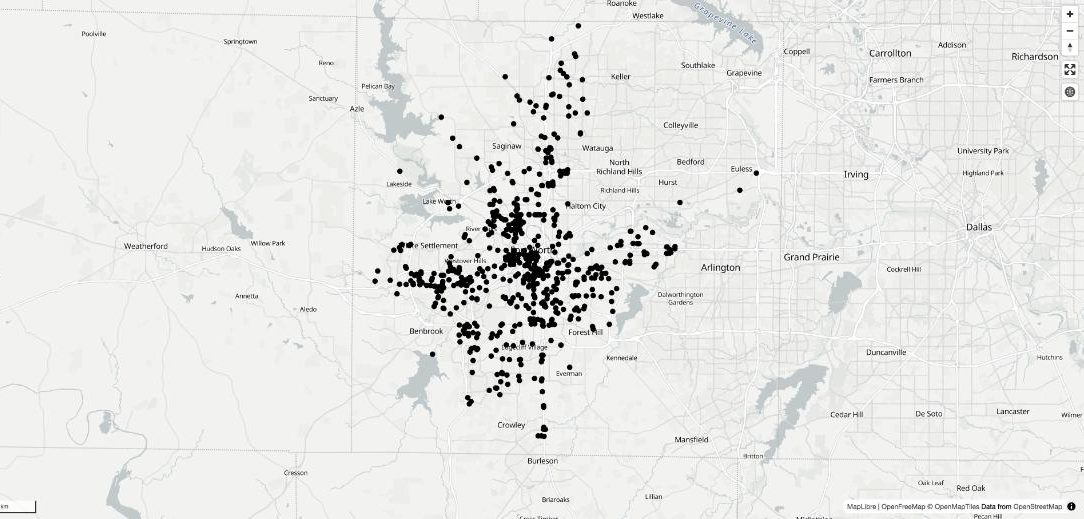

In [10]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "circle", name = "intoxication",
          fit_bounds = False)

m

## Modifying visualization options for your data

By default, your points will show up as black dots on top of your basemap.  While this does show clusters of violations around the city, it is not the most visually pleasing representation of your data.  Let's make some modifications to the data representation to show it in an alternative way.

Layers in MapLibre are styled with _paint properties_, which we can supply as a dictionary to the `paint` parameter.  In the example below, I've made the circles smaller, changed their color, and made them semi-transparent.  Feel free to experiment with different style options; you can modify the circle radius, the color, blur and opacity, and other characteristics.

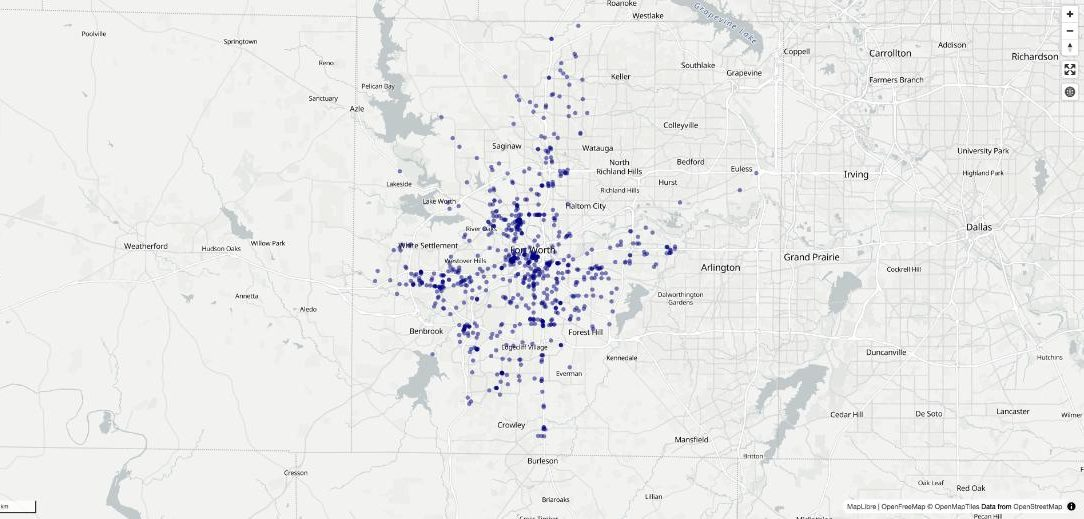

In [11]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "circle", name = "intoxication",
          paint = {"circle-radius": 4,
                   "circle-color": "navy",
                   "circle-opacity": 0.5},
          fit_bounds = False)

m

You are not limited to styling your point data as circles, however.  Let's change the `layer_type` to `"heatmap"`:

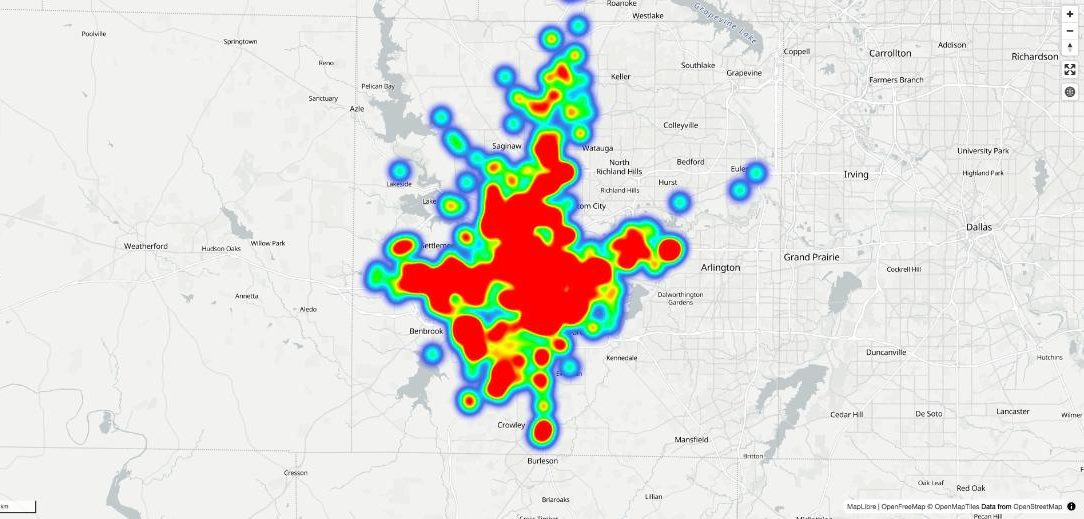

In [12]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "heatmap", name = "intoxication",
          fit_bounds = False)

m

You'll note that your data no longer appears as points, but as a smoothed representation of where your points are concentrated.

The visualization defaults to a blue-to-red representation based on five colors, which each represent different density values.  The highest density value is scaled to 1, which is bright red; the lowest color value is 0.1 by default, colored blue.  Areas without violations are represented without color.  Try zooming in and out on your map to see how the heatmap changes based on zoom level.

There are several ways we can make the map more legible, however; I'll outline a few here.

1. When zoomed out to show the entire city, the high-density areas cover most of the urban core.  This limits our ability to show differentiation on the map.  To modify this, change the radius of your heatmap from the default 30 pixels and make it smaller with the `"heatmap-radius"` paint property.  Experiment with different radii and observe how the data representation changes on your map.

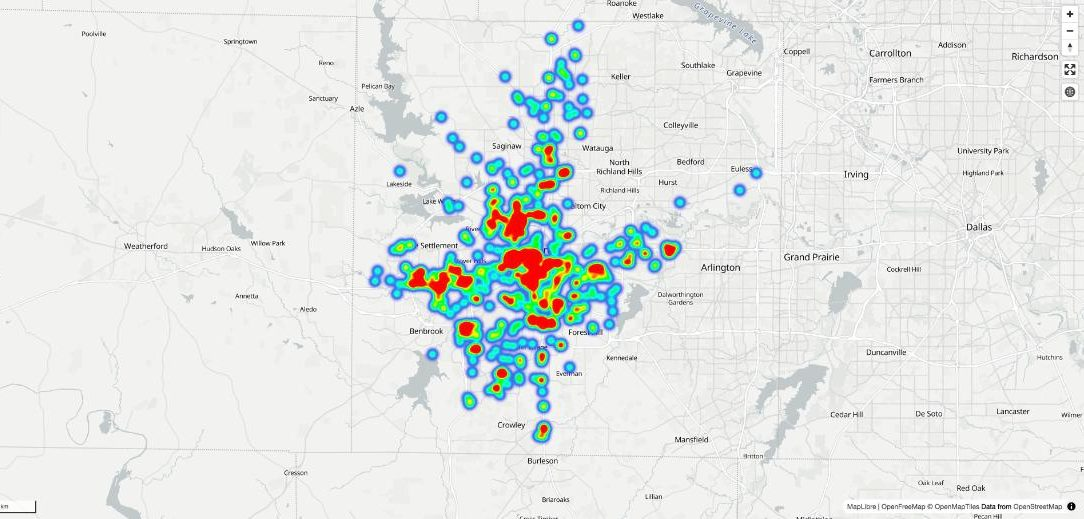

In [13]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "heatmap", name = "intoxication",
          paint = {"heatmap-radius": 15},
          fit_bounds = False)

m

2. The default color representation, while mapping to perceptions of "hot" and "cold" is not colorblindness-safe.  Make some changes to the color values to use a colorblind-safe palette.  I recommend the __viridis__ family of color palettes, which are built into __seaborn__ for quick lookup.  There are five palettes in the viridis family: `viridis`, `magma`, `inferno`, `plasma`, and `cividis`.  All are color-blind safe, perceptually uniform, and safe to print in black and white.  Let's load in the palettes and take a look at them:

In [14]:
import seaborn as sns

viridis = sns.color_palette("viridis", 5).as_hex()
inferno = sns.color_palette("inferno", 5).as_hex()
magma = sns.color_palette("magma", 5).as_hex()
plasma = sns.color_palette("plasma", 5).as_hex()
cividis = sns.color_palette("cividis", 5).as_hex()

I've assigned five-color extracts from the palettes and converted them to hexadecimal representation, which is a common way to represent colors and can be used in MapLibre.  Let's take a look at each palette in turn:

['#443983', '#31688e', '#21918c', '#35b779', '#90d743']


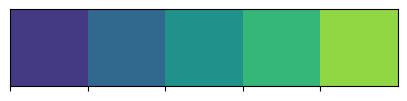

In [15]:
# viridis
print(viridis)
sns.palplot(viridis)

['#320a5e', '#781c6d', '#bc3754', '#ed6925', '#fbb61a']


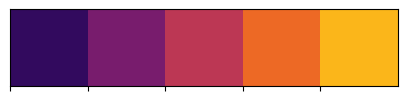

In [16]:
# inferno
print(inferno)
sns.palplot(inferno)

['#2c115f', '#721f81', '#b73779', '#f1605d', '#feb078']


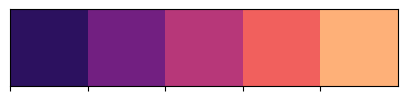

In [17]:
# magma
print(magma)
sns.palplot(magma)

['#5c01a6', '#9c179e', '#cc4778', '#ed7953', '#fdb42f']


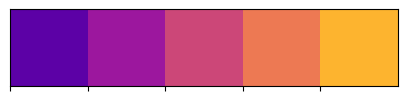

In [18]:
# plasma
print(plasma)
sns.palplot(plasma)

['#2a3f6d', '#575d6d', '#7d7c78', '#a59c74', '#d2c060']


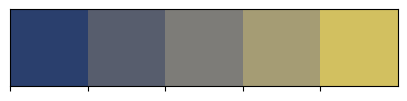

In [19]:
# cividis
print(cividis)
sns.palplot(cividis)

Each sequence ranges from cooler colors to warmer colors, making the colors appropriate for use on a heatmap.  To use one of these palettes, we need to tell MapLibre which color goes with which density value.  This is done with a MapLibre _expression_, which we can write as a Python list.  Read through the code below.  The first line of the expression asks MapLibre to blend smoothly between colors based on the density of the heatmap; each line that follows pairs a density value, called a "stop", with a color.  A density of 0 is given a fully transparent color, so that areas without violations are represented without color.  The stops from 0.1 through 1 are then given the five colors from the `inferno` palette, which we pull from our list by index.

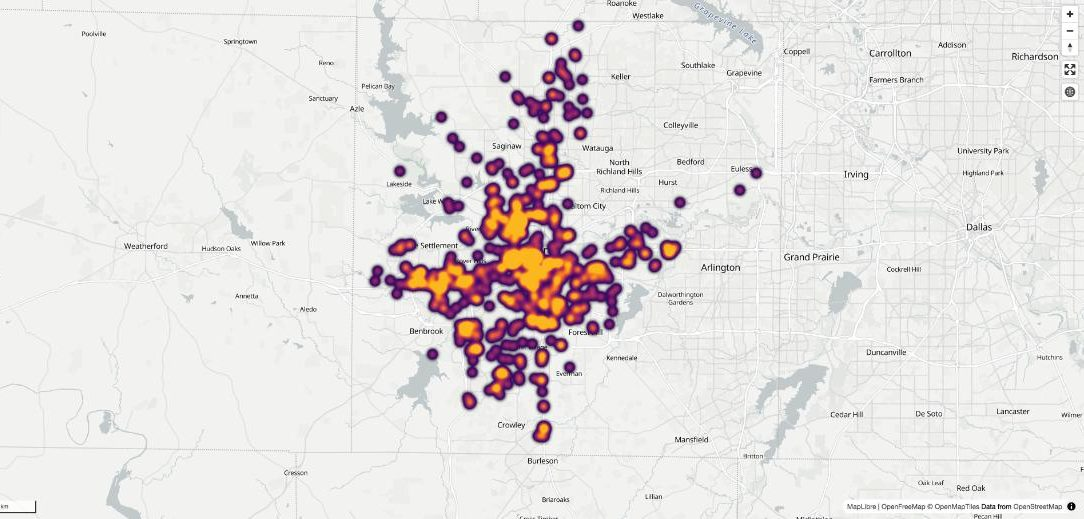

In [20]:
heat_colors = [
    "interpolate", ["linear"], ["heatmap-density"],
    0, "rgba(0, 0, 0, 0)",
    0.1, inferno[0],
    0.3, inferno[1],
    0.5, inferno[2],
    0.7, inferno[3],
    1, inferno[4]
]

m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "heatmap", name = "intoxication",
          paint = {"heatmap-radius": 15,
                   "heatmap-color": heat_colors},
          fit_bounds = False)

m

If you'd like, you can also modify the "stops" that correspond to each color value to tune the color blending accordingly.

3. While the color scheme is now more appropriate, it is difficult to understand _where_ the concentrations of violations are because your heatmap is fully opaque.  Lower the value of the `"heatmap-opacity"` paint property to make your heatmap layer semi-transparent.  You might also consider modifying the `"heatmap-weight"` and `"heatmap-intensity"` properties to make your heatmap less intense.  Experiment with these different options until you achieve a representation that you like.

4. Finally, integrate your heatmap's relationship better with the other map layers by modifying its positioning.  Each element of the basemap - from map labels to roadways to water features - is represented in hierarchical order, with your heatmap layer sitting at the very top.  The `before_id` parameter allows you to place your layer beneath one of the basemap's layers instead.  Here, we use `m.first_symbol_layer_id`, which gives us the first of the label layers in the basemap; note how the visual hierarchy of your map changes, with labels above your heatmap.

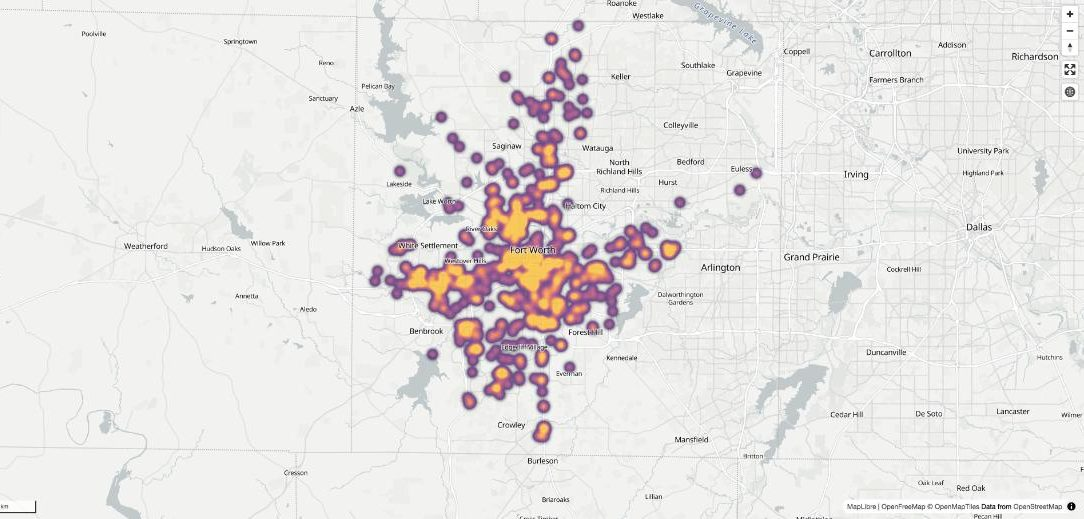

In [21]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_gdf(intox, layer_type = "heatmap", name = "intoxication",
          paint = {"heatmap-radius": 15,
                   "heatmap-color": heat_colors,
                   "heatmap-opacity": 0.7},
          before_id = m.first_symbol_layer_id,
          fit_bounds = False)

m

## Sharing your map

Now that you've made modifications to your map visualization, it is ready to share!  Interactive maps like the ones you've been making are web pages under the hood, and leafmap can write your map to a stand-alone HTML file with the `.to_html()` method.  The HTML file is a text file that can be interpreted by web browsers and rendered as a website.  It can be downloaded and hosted on your personal website, for example.

There is one catch: leafmap can only save the layers of a map that has not yet been displayed in the notebook.  As such, we'll create our map one more time in the cell below, adding the argument `use_message_queue = True` which tells leafmap to hold on to our layers, and save it to a file without displaying it.

In [22]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2",
                use_message_queue = True)

m.add_gdf(intox, layer_type = "heatmap", name = "intoxication",
          paint = {"heatmap-radius": 15,
                   "heatmap-color": heat_colors,
                   "heatmap-opacity": 0.7},
          before_id = m.first_symbol_layer_id,
          fit_bounds = False)

m.to_html("intoxication_map.html", overwrite = True)

When you run this cell, leafmap will write an HTML file named `intoxication_map.html` in your top-level directory in Colab.  Go find it by clicking the folder icon and expand its options; you'll get an option to download the file to the computer, which should default to your Downloads directory.  Once you've downloaded the file, try opening it in a web browser (navigate to the file through your computer's filesystem, then double-click the file to launch it); you'll see your map appear full-screen.

## Analyzing public intoxication by Census tract

The heatmap you've made shows where public intoxication calls are concentrated in Fort Worth.  As you learned in Assignment 6, however, counts can mislead when they are not normalized for population.  In that assignment, we calculated rates by city council district.  Council districts are large, however; each one is home to around 90,000 people, which can hide a lot of variation within them.  In this section, we'll use __Census tracts__ instead.  Census tracts are small areas defined by the US Census Bureau that are typically home to around 4,000 people, and they are commonly used to represent neighborhoods in data analysis.  Working with Census tracts will also allow us to compare public intoxication calls with the demographic characteristics of those neighborhoods.

We'll get our Census tract data with __pytidycensus__, which you learned about in class.  To use it, you'll need a Census API key; replace `"YOUR KEY HERE"` below with the key I've shared with the class.  The call to `get_acs()` then requests two variables from the 2020-2024 American Community Survey for Census tracts in Tarrant County: total population (`B01003_001`) and median age (`B01002_001`).  The argument `geometry = True` returns the data as a GeoDataFrame with the tract boundaries included.

In [23]:
import pytidycensus as tc

tc.set_census_api_key("YOUR KEY HERE")

tracts = tc.get_acs(geography = "tract",
                    variables = {"total_pop": "B01003_001",
                                 "median_age": "B01002_001"},
                    state = "TX", county = "Tarrant",
                    year = 2024, geometry = True)

tracts.head()

Census API key has been set for this session.
Getting data from the 2020-2024 5-year ACS


,GEOID,geometry,total_pop,median_age,state,county,tract,NAME,total_pop_moe,median_age_moe
0,48439105204,"POLYGON ((-97.48116 32.73812, -97.47751 32.738...",4074,27.9,48,439,105204,"Tarrant County, Texas",1212.0,2.3
1,48439105512,"POLYGON ((-97.39588 32.64793, -97.39204 32.648...",5091,39.2,48,439,105512,"Tarrant County, Texas",1027.0,2.3
2,48439104503,"POLYGON ((-97.33175 32.68494, -97.33174 32.688...",2323,34.2,48,439,104503,"Tarrant County, Texas",440.0,5.2
3,48439106202,"POLYGON ((-97.25609 32.72121, -97.25225 32.721...",4583,35.3,48,439,106202,"Tarrant County, Texas",578.0,4.2
4,48439122300,"POLYGON ((-97.12355 32.73583, -97.12351 32.736...",6144,22.1,48,439,122300,"Tarrant County, Texas",621.0,1.1


Let's check the `dtypes` of our two new columns before we do anything with them:

In [24]:
tracts[['total_pop', 'median_age']].dtypes

total_pop      int64
median_age    object
dtype: object

Notice that `total_pop` is stored as integers, but `median_age` is stored as an `object`, which is how `pandas` represents text.  This happens when the Census Bureau does not report a value for one or more of the tracts in a column.  You saw this in class with the income data; we'll need to convert the column to numbers with `pd.to_numeric()` before we can use it.

In [25]:
tracts['median_age'] = pd.to_numeric(tracts['median_age'])

tracts[['total_pop', 'median_age']].dtypes

total_pop       int64
median_age    float64
dtype: object

There is one more issue we need to address before we can combine our datasets.  Our tracts cover all of Tarrant County, which includes Arlington, North Richland Hills, and many other cities.  Our crime data, however, come from the City of Fort Worth alone.  If we kept all of the tracts in the county, tracts in those other cities would show up with zero public intoxication calls, when in reality their calls are handled by other police departments and are missing from our dataset.  To address this, we'll get the boundary of the city of Fort Worth and keep the tracts that fall inside of it, as we did in class for Chicago.

In [26]:
places = tc.get_acs(geography = "place", state = "TX",
                    variables = "B01003_001",
                    year = 2024, geometry = True)

fort_worth = places.query('NAME == "Fort Worth city, Texas"')

# Keep the Tarrant County tracts that fall inside Fort Worth's city limits
fw_tracts = tracts[tracts.representative_point().within(fort_worth.geometry.iloc[0])]

fw_tracts.shape

Getting data from the 2020-2024 5-year ACS


(182, 10)

That leaves us with 182 Census tracts.  The `.representative_point()` method gives us a point that is guaranteed to fall inside each tract; we keep the tracts for which that point is within the Fort Worth city limits.

Now, we can figure out which Census tract each call is located in with a __spatial join__.  As we discussed in class, a spatial join combines two geographic datasets based on their locations rather than on a key field.  Here, we'll match each call to the tract that it falls within.  The two datasets need to share a coordinate reference system for this to work, so we use `.to_crs()` to transform our calls to the CRS used by the tracts.

In [27]:
joined = gp.sjoin(intox.to_crs(fw_tracts.crs), fw_tracts, predicate = "within")

joined.shape

(876, 15)

Our joined dataset has 876 rows, which is fewer than the 909 calls that we started with.  The spatial join only retains the calls that fall within one of our tracts, so the 33 calls located outside of those tracts have been dropped.  It is always a good idea to check your row counts before and after a join like this one, so that you know what you are losing!

From here, the workflow should look familiar from Assignment 6.  We'll count up the calls in each tract, merge the counts back to our tracts, and calculate a rate per 1000 residents.  Note the `how = 'left'` argument in the merge; some tracts did not have any public intoxication calls in 2025, and a left merge makes sure that we keep them.

In [28]:
tract_counts = (joined
    .groupby('GEOID')
    .size()
    .reset_index()
)

tract_counts.columns = ['GEOID', 'count']

fw_merged = fw_tracts.merge(tract_counts, on = 'GEOID', how = 'left')

# Tracts without any calls will have missing values after the merge;
# we fill them in with 0
fw_merged['count'] = fw_merged['count'].fillna(0)

fw_merged['rate'] = (fw_merged['count'] / fw_merged['total_pop']) * 1000

(fw_merged
    .sort_values('rate', ascending = False)
    [['GEOID', 'total_pop', 'median_age', 'count', 'rate']]
    .head()
)

,GEOID,total_pop,median_age,count,rate
105,48439102000,4786,28.6,115.0,24.028416
156,48439101700,1628,38.2,17.0,10.442260
75,48439100202,4277,38.7,44.0,10.287585
102,48439100300,5198,30.7,51.0,9.811466
129,48439123301,1754,33.4,14.0,7.981756


One tract stands out from the rest, with a rate more than twice as high as any other tract in the city.  Let's take a look at where the calls in that tract are located:

In [29]:
joined.query('GEOID == "48439102000"').BLOCK_ADDRESS.value_counts().head()

BLOCK_ADDRESS
2800 BLEDSOE ST    31
1000 FOCH ST       19
900 FOCH ST         7
1100 FOCH ST        7
2800 MORTON ST      6
Name: count, dtype: int64

If you've spent any time in Fort Worth, you may recognize these streets: this is the West 7th entertainment district, just up University Drive from TCU.

Let's map the rates to see how they vary around the city.  A map that shades areas according to their data values is called a __choropleth map__.  The `.add_data()` method in leafmap will draw one for us from a column in our GeoDataFrame.  The `scheme` and `cmap` parameters determine how the tracts are grouped and colored; here, `"Quantiles"` places an equal number of tracts in each of five groups.

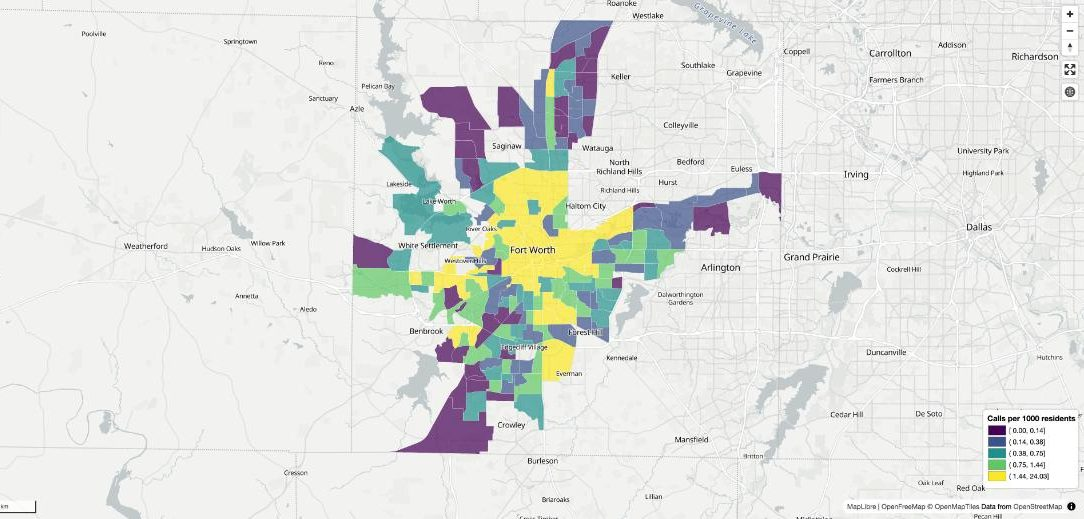

In [30]:
m = leafmap.Map(center = [-97.33, 32.75], zoom = 10, style = "positron2")

m.add_data(fw_merged, column = "rate", scheme = "Quantiles", cmap = "viridis",
           legend_title = "Calls per 1000 residents", name = "rate",
           opacity = 0.7, before_id = m.first_symbol_layer_id,
           fit_bounds = False)

m

Finally, let's take a look at how public intoxication calls relate to the demographics of Fort Worth's neighborhoods.  A reasonable hypothesis might be that neighborhoods with younger populations have higher rates of public intoxication.  As you learned in Assignment 4, we can check this with a scatterplot and a correlation coefficient:

<Axes: xlabel='median_age', ylabel='rate'>

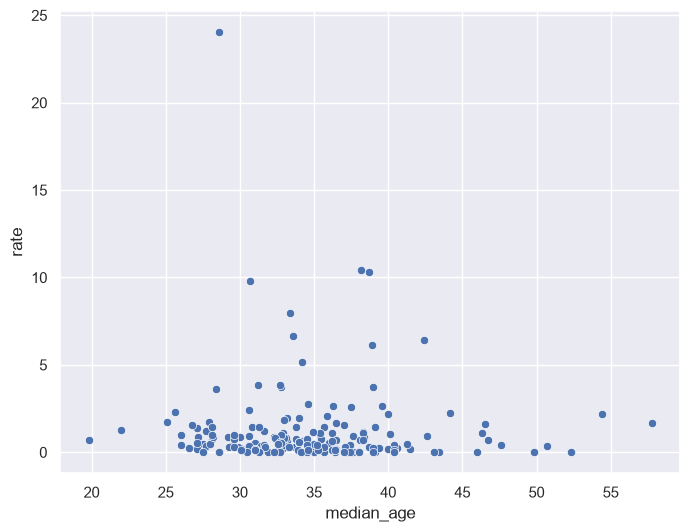

In [31]:
sns.set_theme(style = "darkgrid", rc = {"figure.figsize": (8, 6)})

sns.scatterplot(data = fw_merged, x = "median_age", y = "rate")

In [32]:
fw_merged['rate'].corr(fw_merged['median_age'])

np.float64(-0.03522423334347136)

The hypothesis doesn't hold up very well!  The correlation between the two columns is very close to 0, and the scatterplot shows why.  Most tracts in the city have low rates regardless of the age of their residents, and a small number of tracts have rates far above the rest.  The West 7th tract that we looked at above does have a young population.  People come from all over the region to visit its bars and restaurants, however, so the people involved in those calls don't necessarily live in the neighborhood.  You'll think through this issue some more in the exercises.

## Exercises

Your job in these exercises is to replicate the above analysis for __another type of offense__ in Fort Worth, as you did in Assignment 6.  Use the `.value_counts()` method on the `Nature_Of_Call` column of the `crime` dataset to see what your options are.  You are welcome to use the offense you chose in Assignment 6, or to pick a new one.

To get credit for this assignment, complete the following exercises.

__Exercise 1:__ Use the `crime` dataset to get the 2025 data for your chosen offense.  How many rows are in your dataset, and how many calls do those rows represent?  How many of those calls are missing location information?

__Exercise 2:__ Make an interactive heatmap of your chosen offense.  Choose your own basemap style, heatmap radius, color palette, and opacity.  In a sentence or two, explain why you made the choices that you did.  Then, save your map as an HTML file.

__Exercise 3:__ Calculate the rate of your chosen offense per 1000 residents for Census tracts in Fort Worth, and draw a choropleth map of the rates.  Compare your choropleth map with your heatmap from Exercise 2.  Do the two maps tell the same story about where your offense is concentrated?

__Exercise 4:__ Choose one of the variables from the American Community Survey in the list below and request it for Census tracts in Tarrant County.  Before you draw any charts, write down what kind of relationship you expect to see between your variable and the rate of your chosen offense, and why.  Then, draw a scatterplot and calculate the correlation.  Did the results match your expectations?

* `B19013_001`: median household income
* `B19301_001`: per capita income
* `B25077_001`: median home value
* `B25064_001`: median gross rent
* `B25035_001`: median year in which housing units were built
* `B25010_001`: average household size

Keep in mind that your variable may come back as an `object` column, as median age did; if so, you'll need to convert it with `pd.to_numeric()` before you can use it.

__Exercise 5:__ In this assignment, we calculated rates per 1000 _residents_ of each Census tract.  For public intoxication, we saw that the tract with the highest rate is an entertainment district that people visit from all over the region.  Is the number of residents the right way to normalize public intoxication calls?  What about for your chosen offense?  Explain your reasoning; if you think a different measure would work better, describe what it would be.

To submit your assignment, click the __Share__ button and share your assignment with kwalkertcu@gmail.com.  Additionally, upload the HTML file of your map from Exercise 2 to the submission console in TCU Online.  This will allow me to view your map!